<a href="https://colab.research.google.com/github/Mamidi-Anvesh/retail-review-eda/blob/main/Retail_Review_EDA_Simple_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail Product Review Analysis Using Exploratory Data Analysis (EDA)

**Student:** Anvesh Mamidi  
**Roll No.:** 160125737098  
**Course:** Exploratory Data Analysis & Visualization (EDAV)  
**Department:** Information Technology, CBIT  

### Objective
To study customer ratings and reviews, identify popular product categories, and understand common positive and negative feedback.

## 1. Import libraries and load the dataset
Upload the Women’s Clothing E-Commerce Reviews CSV when prompted. You only need to upload it once per Colab session.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style='whitegrid')

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)
print('Dataset loaded successfully!')
print('Rows and columns:', df.shape)
display(df.head())

Saving Womens Clothing E-Commerce Reviews.csv to Womens Clothing E-Commerce Reviews (1).csv
Dataset loaded successfully!
Rows and columns: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


## 2. Understand the data
Check the column names, data types, missing values, and summary statistics before analysis.

In [5]:
# Remove the unnecessary index column if it exists
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print('Column names:')
print(df.columns.tolist())
print('\nData types and non-missing values:')
df.info()
print('\nMissing values in each column:')
display(df.isnull().sum().to_frame('Missing values'))
print('\nNumerical summary:')
display(df.describe().round(2))

Column names:
['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

Data types and non-missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Clothing ID              23486 non-null  int64 
 1   Age                      23486 non-null  int64 
 2   Title                    19676 non-null  object
 3   Review Text              22641 non-null  object
 4   Rating                   23486 non-null  int64 
 5   Recommended IND          23486 non-null  int64 
 6   Positive Feedback Count  23486 non-null  int64 
 7   Division Name            23472 non-null  object
 8   Department Name          23472 non-null  object
 9   Class Name               23472 non-null  object
dtypes: int64(5), object(5)
memory usage: 1.8+ MB

M

,Missing values
Clothing ID,0
Age,0
Title,3810
Review Text,845
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,14
Department Name,14
Class Name,14



Numerical summary:


,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.00,23486.00,23486.00,23486.00,23486.00
mean,918.12,43.20,4.20,0.82,2.54
std,203.30,12.28,1.11,0.38,5.70
min,0.00,18.00,1.00,0.00,0.00
25%,861.00,34.00,4.00,1.00,0.00
50%,936.00,41.00,5.00,1.00,1.00
75%,1078.00,52.00,5.00,1.00,3.00
max,1205.00,99.00,5.00,1.00,122.00


## 3. Clean the data
For this analysis, remove exact duplicate rows, keep valid ratings from 1 to 5, and prepare review text for analysis. Missing review text is not invented.

In [6]:
start_rows = len(df)
df = df.drop_duplicates().copy()
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
df = df[df['Rating'].between(1, 5)].copy()

for col in ['Title', 'Review Text']:
    if col in df.columns:
        df[col] = df[col].fillna('').astype(str).str.strip()

df['Full Review'] = (df['Title'] + ' ' + df['Review Text']).str.strip()
df['Review Length'] = df['Review Text'].str.split().str.len()
print('Rows before cleaning:', start_rows)
print('Rows after cleaning:', len(df))
print('Duplicate/invalid rows removed:', start_rows - len(df))
display(df.head())

Rows before cleaning: 23486
Rows after cleaning: 23465
Duplicate/invalid rows removed: 21


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Full Review,Review Length
0,767,33,,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,Absolutely wonderful - silky and sexy and comf...,8
1,1080,34,,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,Love this dress! it's sooo pretty. i happene...,62
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,Some major design flaws I had such high hopes ...,98
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,"My favorite buy! I love, love, love this jumps...",22
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,Flattering shirt This shirt is very flattering...,36


## 4. Rating distribution
This chart shows how many customers gave each star rating. The average rating gives a simple overall picture of customer satisfaction.

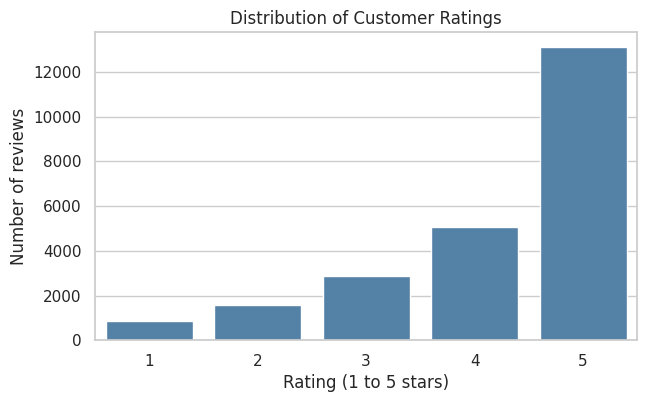

Average rating: 4.2 / 5
Median rating: 5.0
Percentage of 4-5 star reviews: 77.51 %


In [7]:
rating_counts = df['Rating'].value_counts().sort_index()
plt.figure(figsize=(7, 4))
sns.barplot(x=rating_counts.index, y=rating_counts.values, color='steelblue')
plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating (1 to 5 stars)')
plt.ylabel('Number of reviews')
plt.show()
print('Average rating:', round(df['Rating'].mean(), 2), '/ 5')
print('Median rating:', df['Rating'].median())
print('Percentage of 4-5 star reviews:', round(df['Rating'].isin([4, 5]).mean() * 100, 2), '%')

## 5. Ratings by department
Compare the average rating and number of reviews for each department. A group with more reviews has more customer feedback in this dataset.

,Number_of_Reviews,Average_Rating
Department Name,,
Tops,10455,4.17
Dresses,6312,4.15
Bottoms,3798,4.29
Intimate,1735,4.28
Jackets,1032,4.26
Trend,119,3.82


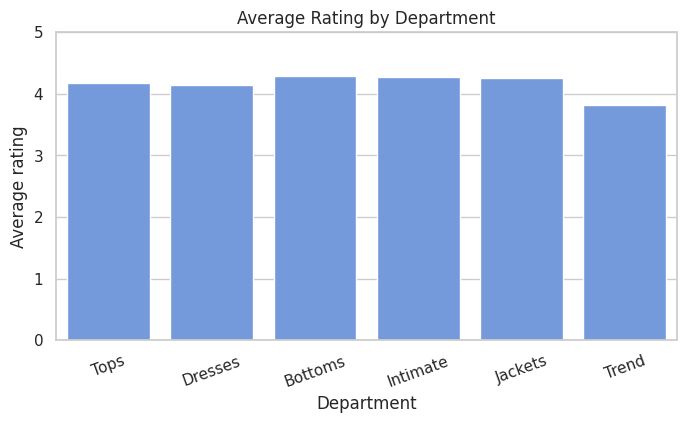

In [8]:
if 'Department Name' in df.columns:
    dept_summary = df.groupby('Department Name').agg(
        Number_of_Reviews=('Rating', 'size'),
        Average_Rating=('Rating', 'mean')
    ).sort_values('Number_of_Reviews', ascending=False)
    display(dept_summary.round(2))
    plt.figure(figsize=(8, 4))
    sns.barplot(data=dept_summary.reset_index(), x='Department Name', y='Average_Rating', color='cornflowerblue')
    plt.ylim(0, 5)
    plt.title('Average Rating by Department')
    plt.xlabel('Department')
    plt.ylabel('Average rating')
    plt.xticks(rotation=20)
    plt.show()

## 6. Product categories with the most reviews
This helps identify which types of clothing received the most customer feedback.

,Number of reviews
Class Name,
Dresses,6312
Knits,4835
Blouses,3093
Sweaters,1428
Pants,1388
Jeans,1146
Fine gauge,1099
Skirts,945
Jackets,704


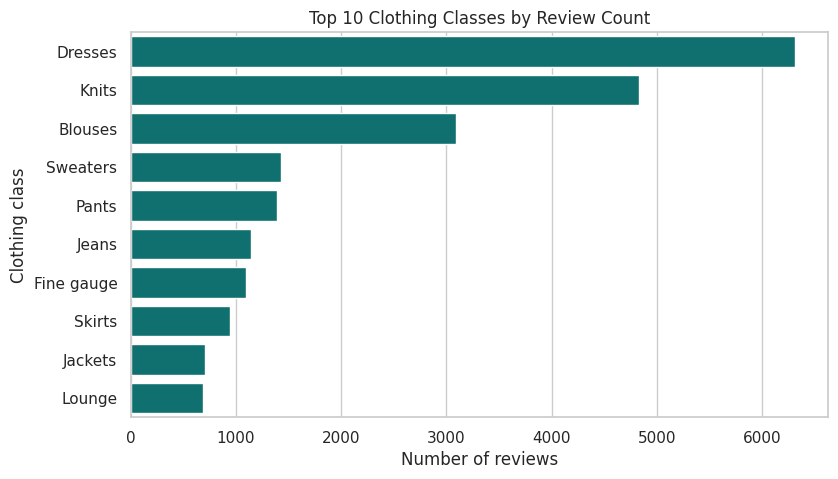

In [9]:
if 'Class Name' in df.columns:
    class_counts = df['Class Name'].value_counts().head(10)
    display(class_counts.to_frame('Number of reviews'))
    plt.figure(figsize=(9, 5))
    sns.barplot(x=class_counts.values, y=class_counts.index, color='teal')
    plt.title('Top 10 Clothing Classes by Review Count')
    plt.xlabel('Number of reviews')
    plt.ylabel('Clothing class')
    plt.show()

## 7. Recommendation analysis
Compare customers who recommended the product with those who did not, where the dataset provides that information.

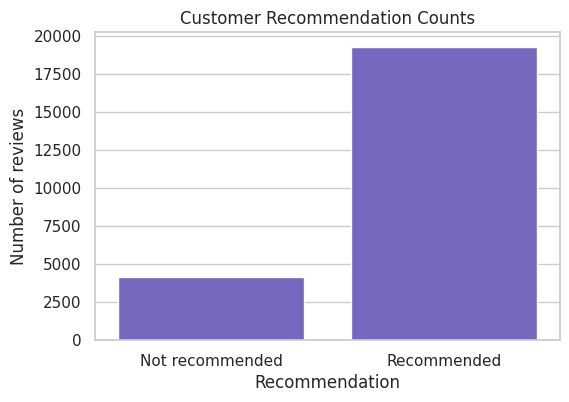

Recommendation percentages:


,Percentage
Recommended IND,
Recommended,82.22
Not recommended,17.78


In [10]:
if 'Recommended IND' in df.columns:
    recommendation_counts = df['Recommended IND'].value_counts().sort_index()
    labels = {0: 'Not recommended', 1: 'Recommended'}
    plt.figure(figsize=(6, 4))
    sns.barplot(x=[labels.get(i, str(i)) for i in recommendation_counts.index],
                y=recommendation_counts.values, color='slateblue')
    plt.title('Customer Recommendation Counts')
    plt.xlabel('Recommendation')
    plt.ylabel('Number of reviews')
    plt.show()
    print('Recommendation percentages:')
    display((df['Recommended IND'].value_counts(normalize=True) * 100).rename(index=labels).round(2).to_frame('Percentage'))

## 8. Common words in reviews
A simple word count gives an idea of what customers frequently mention. This is a basic exploration, not a full understanding of sentence meaning.

,Word,Count
0,top,8595
1,great,7908
2,like,7386
3,fabric,5082
4,small,5069
5,color,4916
6,cute,4596
7,perfect,4590
8,beautiful,4372
9,can,4136


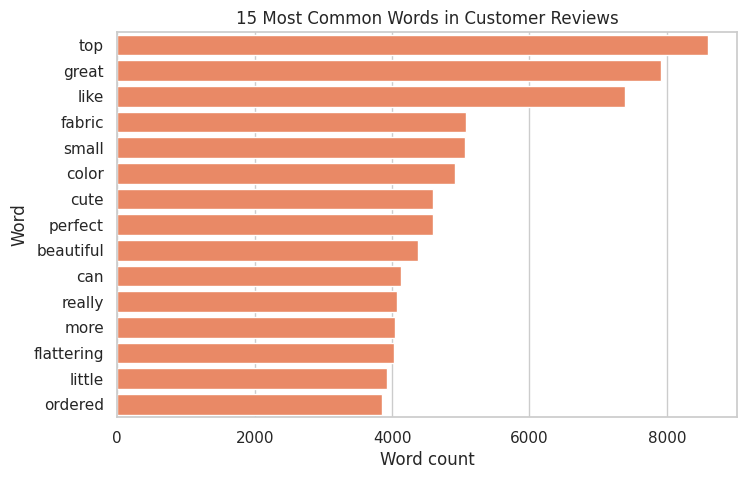

In [11]:
import re
from collections import Counter

text = ' '.join(df['Full Review'].dropna().astype(str)).lower()
words = re.findall(r"\b[a-z]{3,}\b", text)
stop_words = set('the and for that this with was are but not you your have had has very they them from too its she her his would could about product dress shirt size fit wear love look one just'.split())
words = [w for w in words if w not in stop_words]
top_words = Counter(words).most_common(15)
word_df = pd.DataFrame(top_words, columns=['Word', 'Count'])
display(word_df)
plt.figure(figsize=(8, 5))
sns.barplot(data=word_df, x='Count', y='Word', color='coral')
plt.title('15 Most Common Words in Customer Reviews')
plt.xlabel('Word count')
plt.ylabel('Word')
plt.show()

## 9. Final observations
Run the notebook from top to bottom and use the actual outputs above to state your findings. The observations below are generated from the dataset rather than typed in advance.

In [12]:
print('PROJECT SUMMARY')
print('Total reviews analysed:', len(df))
print('Average rating:', round(df['Rating'].mean(), 2), 'out of 5')
print('Reviews with 4 or 5 stars:', round(df['Rating'].isin([4, 5]).mean() * 100, 2), '%')
if 'Department Name' in df.columns:
    print('Department with most reviews:', df['Department Name'].value_counts().idxmax())
if 'Class Name' in df.columns:
    print('Clothing class with most reviews:', df['Class Name'].value_counts().idxmax())
if 'Recommended IND' in df.columns:
    print('Recommendation rate:', round(df['Recommended IND'].mean() * 100, 2), '%')
print('Average review length:', round(df['Review Length'].mean(), 1), 'words')

PROJECT SUMMARY
Total reviews analysed: 23465
Average rating: 4.2 out of 5
Reviews with 4 or 5 stars: 77.51 %
Department with most reviews: Tops
Clothing class with most reviews: Dresses
Recommendation rate: 82.22 %
Average review length: 58.1 words


## 10. Conclusion
This project uses exploratory data analysis to examine customer ratings, department and clothing-class review counts, recommendations, and frequently used review words. The charts help summarize customer feedback and may point to areas that retailers can investigate further. The analysis describes patterns in this dataset and does not prove why customers gave particular ratings.